# SWIR inspection notebook — look before you model

A light pass over your cubes. No ROIs to type in, no modelling. It opens every `.hdr` on the drive,
renders images you can actually look at, works out where the objects are on its own, converts to
reflectance, and plots spectra.

**What you do:**

1. Set `DATA_DIR` in the config cell and run top to bottom.
2. Look at the quicklooks in section 3.
3. Send me the PNGs from `./quicklooks/` **and** the text block printed by the last cell.
4. Tell me the specimen arrangement.

The last cell prints a compact summary — header facts, detected object boxes, brightness stats, whether
the reflectance conversion checks out. That text is often more useful to me than the images, because it
carries exact pixel coordinates. Send both.

**What this notebook figures out by itself:**

- which files pair up, and whether any `.img` is missing or truncated;
- where the objects are (dishes and reference target), as bounding boxes in pixel coordinates;
- whether the dishes run along-track or across-track;
- where the four steps of the reference target sit;
- whether the radiance is already dark-corrected;
- whether the reflectance conversion reproduces the certified step values.

Auto-detection can be wrong. Every detected region can be overridden by hand, and section 5 shows you
what it found so you can check it against the picture.

## 1. Setup

Only `DATA_DIR` normally needs changing. The panel certificate path assumes you copied
`SRT-MS-050__1_.txt` next to this notebook, as in the setup steps.

In [1]:
import os, re, json, textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "figure.facecolor": "white"})
np.set_printoptions(suppress=True, precision=3)

# ---------------------------- EDIT ----------------------------
DATA_DIR  = Path(os.environ.get("COFFEE_DATA", "."))
PANEL_TXT = Path("./SRT-MS-050__1_.txt")
# --------------------------------------------------------------

QL_DIR = Path("./quicklooks"); QL_DIR.mkdir(exist_ok=True)
OUT    = Path("./inspect_out"); OUT.mkdir(exist_ok=True)

print("data dir exists:", DATA_DIR.exists())
print("panel file exists:", PANEL_TXT.exists())

data dir exists: True
panel file exists: False


## 2. Open the cubes

The reader is a plain `numpy.memmap` — nothing is loaded into RAM until a region is sliced, so six
884 MB cubes cost nothing to open.

Your header declares `header offset = 2666496`, which is not a whole number of BIL lines. That is unusual
enough not to trust, so the reader checks it against the actual file size and reports which interpretation
it used. If a file is truncated or a `.img` is missing, you find out here rather than three sections later.

In [2]:
ENVI_DTYPES = {1:"u1", 2:"i2", 3:"i4", 4:"f4", 5:"f8", 12:"u2", 13:"u4", 14:"i8", 15:"u8"}

def parse_envi_header(hdr_path):
    txt = Path(hdr_path).read_text(errors="ignore").replace("\r", "")
    if not txt.lstrip().startswith("ENVI"):
        raise ValueError(f"{hdr_path} is not an ENVI header")
    body = txt.split("\n", 1)[1] if "\n" in txt else ""
    out, pos = {}, 0
    pat = re.compile(r"^\s*([\w\s]+?)\s*=\s*(\{.*?\}|[^\n]*)", re.S | re.M)
    while pos < len(body):
        m = pat.search(body, pos)
        if not m: break
        key, val = m.group(1).strip().lower(), m.group(2).strip()
        if val.startswith("{") and not val.endswith("}"):
            end = body.find("}", m.end(2)); val = body[m.start(2):end+1]; pos = end + 1
        else:
            pos = m.end(2)
        out[key] = val
    for k in ["samples", "lines", "bands", "header offset", "data type", "byte order"]:
        if k in out: out[k] = int(float(out[k]))
    if "data ignore value" in out: out["data ignore value"] = float(out["data ignore value"])
    if "wavelength" in out:
        out["wavelength"] = np.array([float(x) for x in
            out["wavelength"].strip("{}").replace("\n", " ").split(",") if x.strip()])
    out["interleave"] = out.get("interleave", "bsq").strip().lower()
    return out


def find_data_file(hdr_path):
    hdr_path = Path(hdr_path); stem = hdr_path.with_suffix("")
    cands = [stem.with_suffix(e) for e in (".img", ".raw", ".dat", ".bin", ".bil", "")]
    cands.append(Path(str(hdr_path) + ".img"))
    for c in cands:
        if c.exists() and c.is_file() and c != hdr_path: return c
    return None


class Cube:
    def __init__(self, hdr_path):
        self.hdr_path = Path(hdr_path)
        self.h = parse_envi_header(hdr_path)
        self.path = find_data_file(hdr_path)
        if self.path is None:
            raise FileNotFoundError(f"no data file beside {self.hdr_path.name}")
        L, S, B = self.h["lines"], self.h["samples"], self.h["bands"]
        dtc = ENVI_DTYPES[self.h["data type"]]
        nbytes = L * S * B * np.dtype(dtc).itemsize
        fsize = self.path.stat().st_size
        declared = self.h.get("header offset", 0)
        if fsize == declared + nbytes:   off, why = declared, "declared offset matches"
        elif fsize == nbytes:            off, why = 0, "no offset (file == data size)"
        elif fsize > nbytes and fsize - nbytes < 10_000_000:
            off, why = fsize - nbytes, f"offset inferred as {fsize - nbytes}"
        else:
            raise ValueError(f"{self.path.name}: size {fsize} vs expected {nbytes} (+{declared}). "
                             f"File may be truncated.")
        self.offset, self.offset_reason = off, why
        dt = np.dtype(dtc).newbyteorder("<" if self.h.get("byte order", 0) == 0 else ">")
        shape = {"bil": (L, B, S), "bsq": (B, L, S), "bip": (L, S, B)}[self.h["interleave"]]
        mm = np.memmap(self.path, dtype=dt, mode="r", offset=off, shape=shape)
        self.arr = {"bil": mm.transpose(0, 2, 1), "bsq": mm.transpose(1, 2, 0), "bip": mm}[self.h["interleave"]]
        self.wl = self.h["wavelength"]
        self.ignore = self.h.get("data ignore value", None)

    @property
    def shape(self): return self.arr.shape

    def bands_near(self, nm_list):
        return [int(np.argmin(np.abs(self.wl - nm))) for nm in np.atleast_1d(nm_list)]

    def region(self, r0, r1, c0, c1):
        blk = np.array(self.arr[r0:r1, c0:c1, :], dtype=np.float32)   # np.array => writable copy
        if self.ignore is not None: blk[blk == self.ignore] = np.nan
        return blk

    def brightness(self, step=2, lo=1500, hi=1700):
        # Decimated mean-radiance image over a clean band window. Cheap: BIL means a
        # few bands of every Nth line is a small scattered read, not the whole cube.
        idx = [i for i, w in enumerate(self.wl) if lo <= w <= hi][:8]
        sub = np.array(self.arr[::step, ::step, :][:, :, idx], dtype=np.float32)
        if self.ignore is not None: sub[sub == self.ignore] = np.nan
        return np.nanmean(sub, axis=2), step

    def __repr__(self):
        return f"<Cube {self.hdr_path.name} {self.shape} {self.h['interleave']} off={self.offset}>"

In [3]:
hdrs = sorted(DATA_DIR.rglob("*.hdr"))
print(f"found {len(hdrs)} .hdr files under {DATA_DIR}\n")

CUBES, problems = {}, []
for h in hdrs:
    try:
        c = Cube(h)
        CUBES[h.stem] = c
        gb = c.path.stat().st_size / 1e9
        print(f"  OK  {h.name}")
        print(f"      {c.shape[0]} lines x {c.shape[1]} samples x {c.shape[2]} bands | "
              f"{gb:.2f} GB | {c.offset_reason}")
        print(f"      {c.wl[0]:.1f} - {c.wl[-1]:.1f} nm | ignore={c.ignore}")
    except Exception as e:
        problems.append((h.name, str(e)))
        print(f"  !!  {h.name}: {e}")

if problems:
    print("\nFiles that could not be opened -- resolve these before going further:")
    for n, e in problems: print(f"  {n}: {e}")

wls = {k: tuple(np.round(c.wl, 3)) for k, c in CUBES.items()}
if len(set(wls.values())) > 1:
    print("\nWARNING: not all cubes share the same band list. Do not stack them without checking.")
else:
    print("\nall cubes share the same band list")

found 6 .hdr files under /run/media/riyanvarghese/RIYAN HDD/coffee data

  OK  stir1_SWIR_384_SN3189_9000us_2026-09-01T162127_raw_rad_float32.hdr
      2000 lines x 384 samples x 288 bands | 0.89 GB | declared offset matches
      952.2 - 2516.6 nm | ignore=2.0
  OK  stir1_SWIR_384_SN3189_9000us_2026-09-04T161044_raw_rad_float32.hdr
      1700 lines x 384 samples x 288 bands | 0.75 GB | declared offset matches
      952.2 - 2516.6 nm | ignore=2.0
  OK  stir2_SWIR_384_SN3189_9000us_2026-09-01T163234_raw_rad_float32.hdr
      2000 lines x 384 samples x 288 bands | 0.89 GB | declared offset matches
      952.2 - 2516.6 nm | ignore=2.0
  OK  stir2_SWIR_384_SN3189_9000us_2026-09-04T161928_raw_rad_float32.hdr
      1700 lines x 384 samples x 288 bands | 0.75 GB | declared offset matches
      952.2 - 2516.6 nm | ignore=2.0
  OK  stir3_SWIR_384_SN3189_9000us_2026-09-01T164219_raw_rad_float32.hdr
      2000 lines x 384 samples x 288 bands | 0.89 GB | declared offset matches
      952.2 - 2516.

## 3. Quicklooks

Two views of each cube:

- a **greyscale brightness image** at ~1600 nm, which is where the scene is bright and featureless, so
  shapes read clearly;
- a **false-colour composite** (2200 / 1650 / 1200 nm), where materials that differ chemically take on
  different hues — chicory and coffee should not look identical here.

Both are saved to `./quicklooks/` as PNGs. Axes are in raw pixel coordinates with a grid, so you can read
positions straight off them — that is what makes them useful to send me.

`aspect="auto"` stretches the image to fit the figure, so the shapes will look distorted if your
along-track and across-track sampling differ. That is deliberate: it keeps long scans readable. The true
proportions come from section 4.

saved quicklooks/stir1_SWIR_384_SN3189_9000us_2026-09-01T162127_raw_rad_float32_quicklook.png


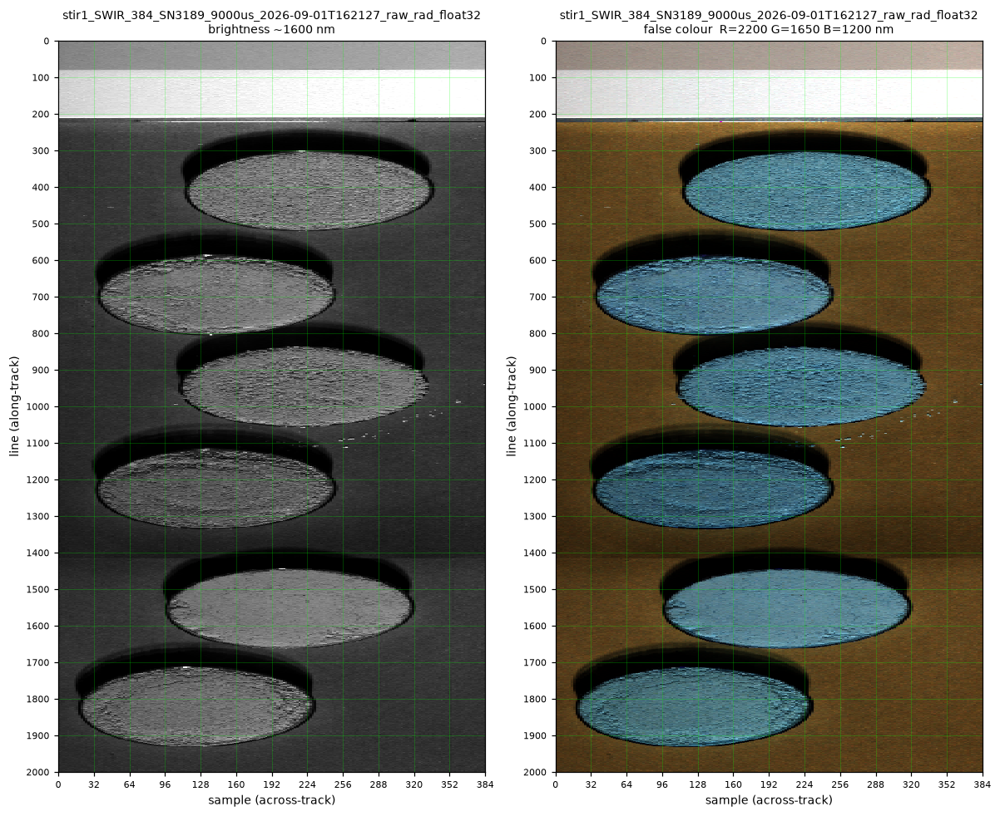

saved quicklooks/stir1_SWIR_384_SN3189_9000us_2026-09-04T161044_raw_rad_float32_quicklook.png


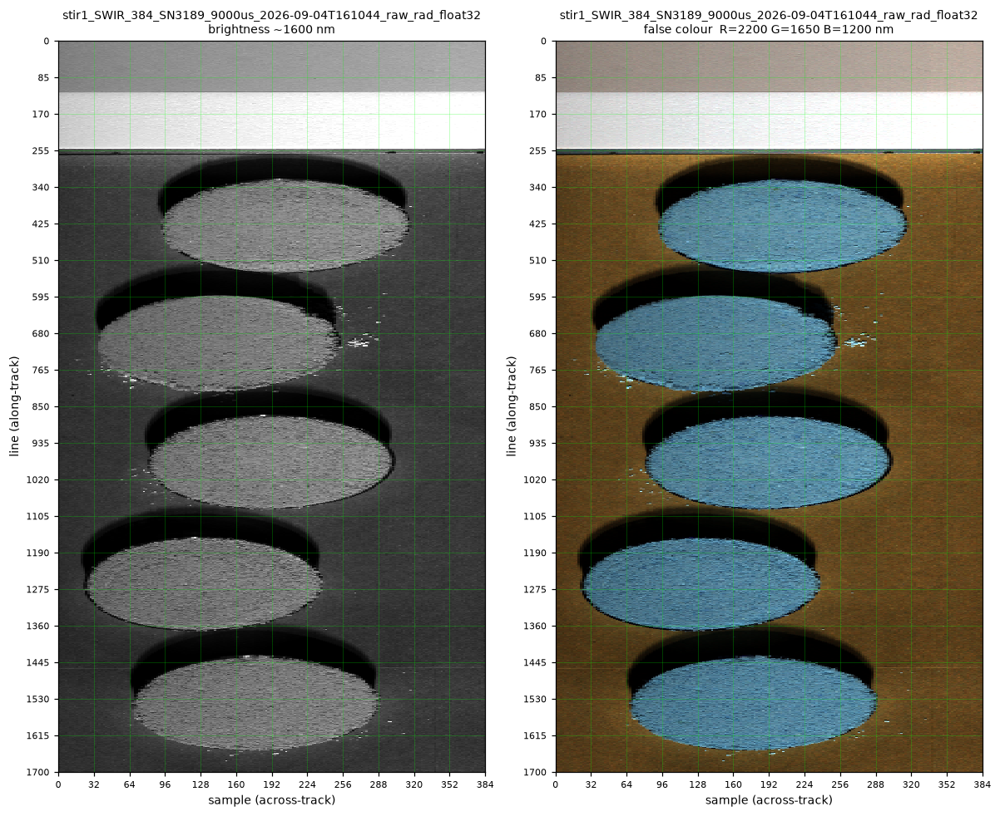

saved quicklooks/stir2_SWIR_384_SN3189_9000us_2026-09-01T163234_raw_rad_float32_quicklook.png


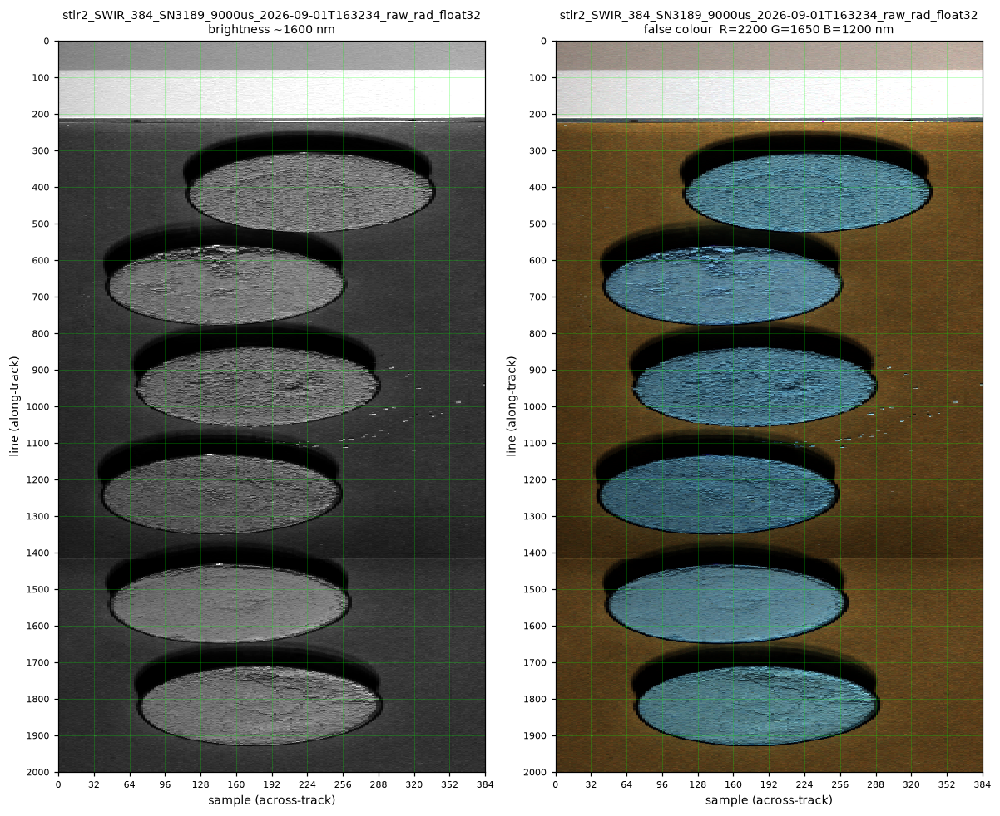

saved quicklooks/stir2_SWIR_384_SN3189_9000us_2026-09-04T161928_raw_rad_float32_quicklook.png


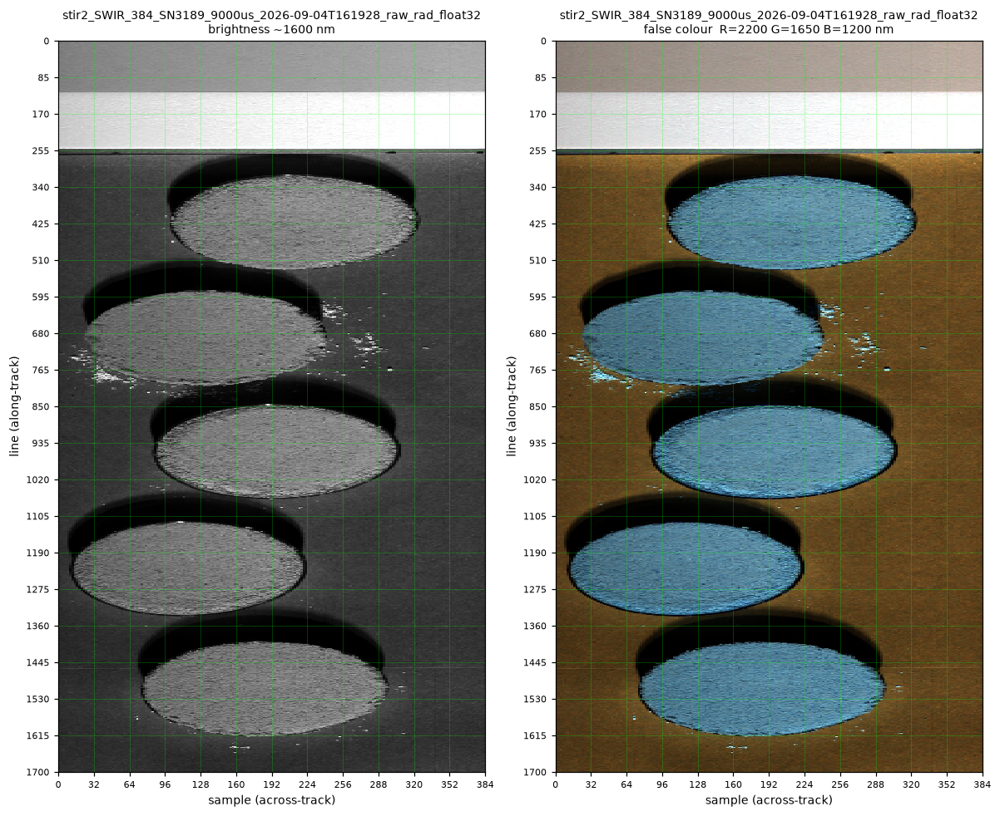

saved quicklooks/stir3_SWIR_384_SN3189_9000us_2026-09-01T164219_raw_rad_float32_quicklook.png


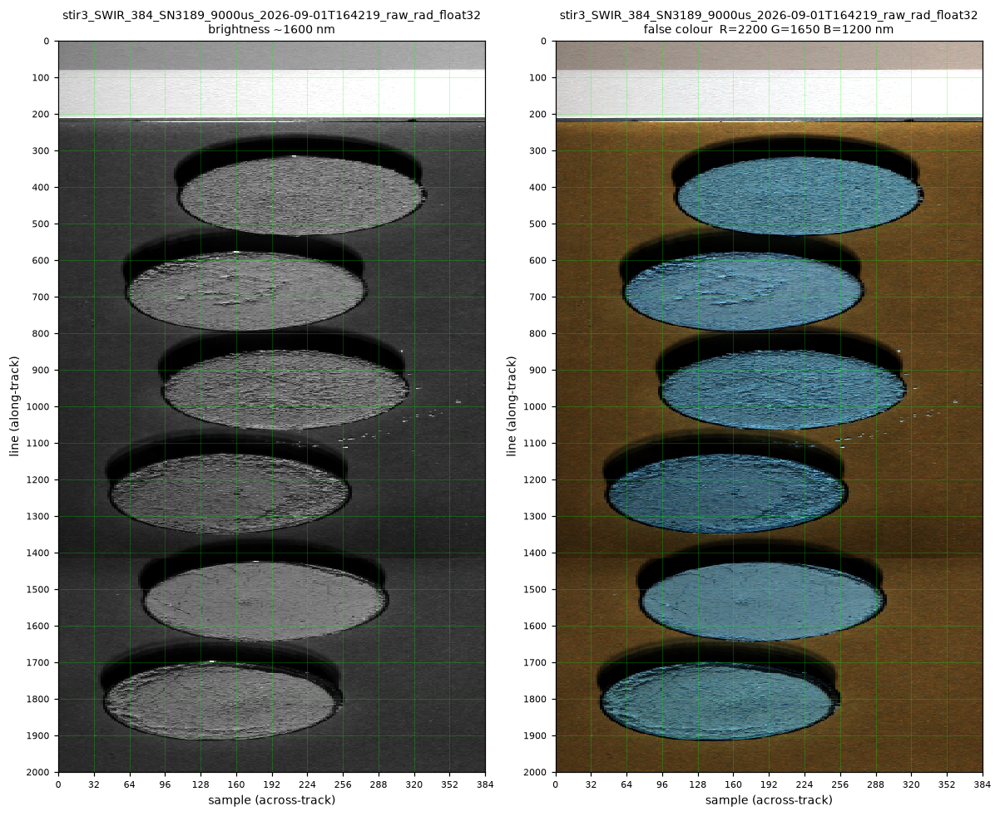

saved quicklooks/stir3_SWIR_384_SN3189_9000us_2026-09-04T162700_raw_rad_float32_quicklook.png


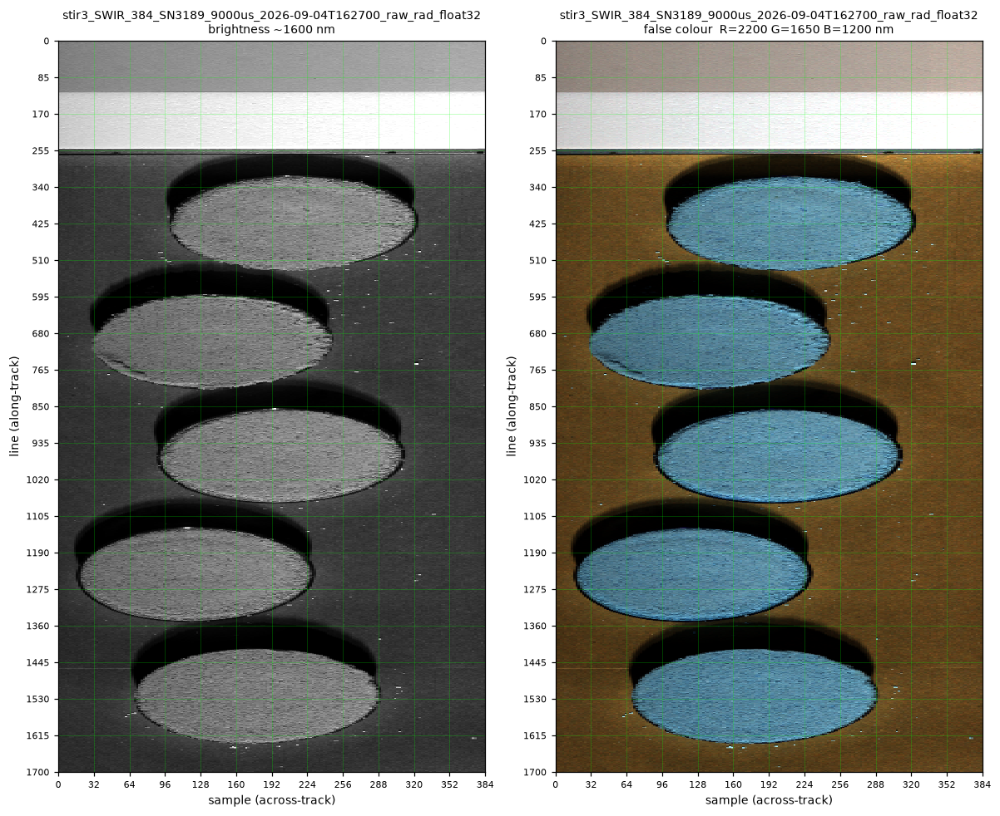

In [4]:
def stretch(a, lo=2, hi=98):
    l, h = np.nanpercentile(a, [lo, hi])
    return np.clip((a - l) / max(h - l, 1e-9), 0, 1)

def quicklook(cube, key, step=2, save=True):
    bright, st = cube.brightness(step=step)
    idx = cube.bands_near([2200, 1650, 1200])
    rgb_raw = np.array(cube.arr[::step, ::step, :][:, :, idx], dtype=np.float32)
    if cube.ignore is not None: rgb_raw[rgb_raw == cube.ignore] = np.nan
    rgb = np.dstack([stretch(rgb_raw[..., k]) for k in range(3)])
    rgb = np.nan_to_num(rgb)

    L, S = cube.shape[0], cube.shape[1]
    fig, axs = plt.subplots(1, 2, figsize=(11, 9))
    for ax, im, ttl in [(axs[0], stretch(bright), "brightness ~1600 nm"),
                        (axs[1], rgb, "false colour  R=2200 G=1650 B=1200 nm")]:
        ax.imshow(im, cmap="gray" if im.ndim == 2 else None,
                  extent=[0, S, L, 0], aspect="auto", interpolation="nearest")
        ax.set_title(f"{key}\n{ttl}", fontsize=9)
        ax.set_xlabel("sample (across-track)"); ax.set_ylabel("line (along-track)")
        ax.set_xticks(np.arange(0, S + 1, max(32, S // 12)))
        ax.set_yticks(np.arange(0, L + 1, max(50, L // 20)))
        ax.grid(color="lime", alpha=.3, lw=.5)
        ax.tick_params(labelsize=7)
    plt.tight_layout()
    if save:
        p = QL_DIR / f"{key}_quicklook.png"
        fig.savefig(p, dpi=130, bbox_inches="tight")
        print("saved", p)
    plt.show()
    return bright, st

BRIGHT = {}
for key, cube in CUBES.items():
    BRIGHT[key] = quicklook(cube, key)

## 4. Where are the specimens?

You said the dishes sit "from the reference" in order, which reads like they run **along** the scan
direction rather than across the swath — but that changes which nuisance effect is dangerous, so it is
worth confirming from the data instead of assuming.

The profiles below collapse the brightness image onto each axis. Objects separated by dark gaps show up as
a train of bumps on one axis and a single broad plateau on the other. Whichever axis has the bumps is the
axis the specimens are arranged along.

Why it matters: if they run **across-track**, dish position is aliased with the illumination and vignetting
profile of the lens, and position is confounded with concentration. If they run **along-track**, position
maps to *time* during the ~82-second scan, so the risk is lamp drift instead. Both are manageable, but they
need different diagnostics.

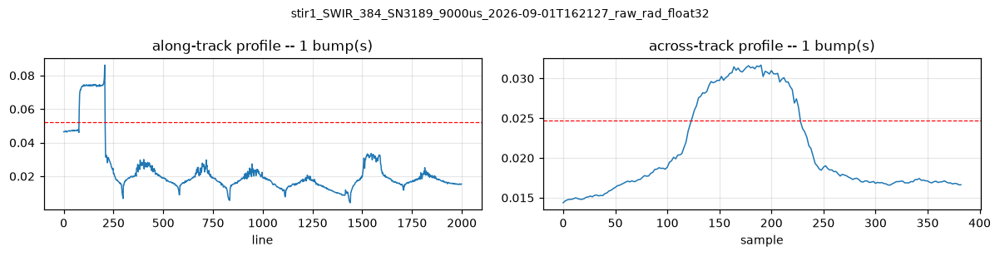

stir1_SWIR_384_SN3189_9000us_2026-09-01T162127_raw_rad_float32: specimens appear to be arranged along-track (down the scan)


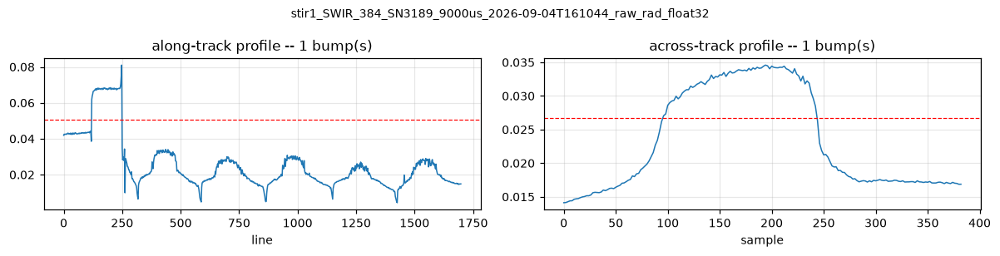

stir1_SWIR_384_SN3189_9000us_2026-09-04T161044_raw_rad_float32: specimens appear to be arranged along-track (down the scan)


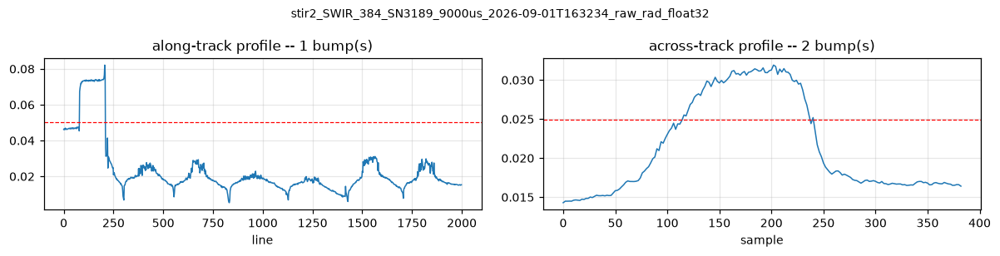

stir2_SWIR_384_SN3189_9000us_2026-09-01T163234_raw_rad_float32: specimens appear to be arranged across-track (over the swath)


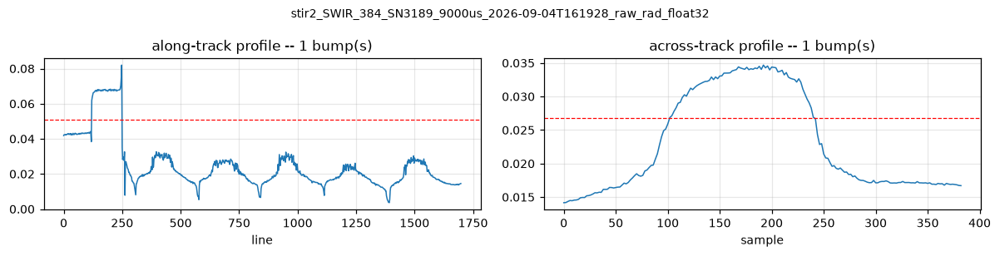

stir2_SWIR_384_SN3189_9000us_2026-09-04T161928_raw_rad_float32: specimens appear to be arranged along-track (down the scan)


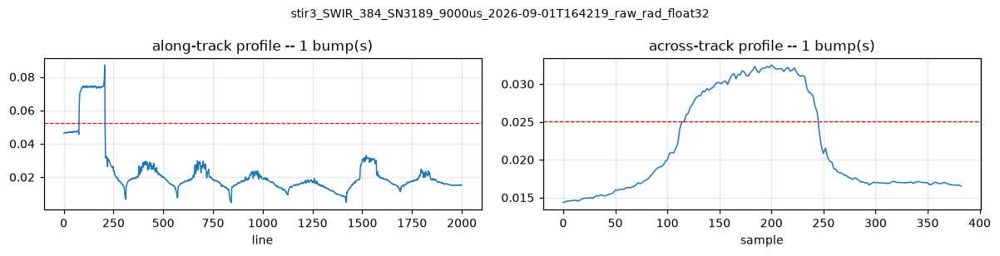

stir3_SWIR_384_SN3189_9000us_2026-09-01T164219_raw_rad_float32: specimens appear to be arranged along-track (down the scan)


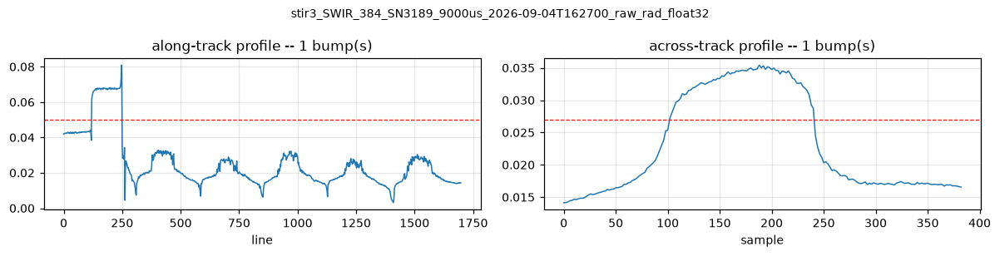

stir3_SWIR_384_SN3189_9000us_2026-09-04T162700_raw_rad_float32: specimens appear to be arranged along-track (down the scan)


In [5]:
def layout_profiles(bright, key, st):
    along  = np.nanmedian(bright, axis=1)     # one value per line
    across = np.nanmedian(bright, axis=0)     # one value per sample

    def n_bumps(p):
        p = np.nan_to_num(p); t = (p.max() + np.median(p)) / 2
        m = p > t
        return int(np.sum(np.diff(m.astype(int)) == 1)), t

    nb_a, ta = n_bumps(along); nb_c, tc = n_bumps(across)
    fig, axs = plt.subplots(1, 2, figsize=(11, 2.8))
    axs[0].plot(np.arange(along.size) * st, along, lw=1)
    axs[0].axhline(ta, color="r", ls="--", lw=.8)
    axs[0].set_title(f"along-track profile -- {nb_a} bump(s)"); axs[0].set_xlabel("line")
    axs[1].plot(np.arange(across.size) * st, across, lw=1)
    axs[1].axhline(tc, color="r", ls="--", lw=.8)
    axs[1].set_title(f"across-track profile -- {nb_c} bump(s)"); axs[1].set_xlabel("sample")
    for ax in axs: ax.grid(alpha=.3)
    fig.suptitle(key, fontsize=9); plt.tight_layout()
    fig.savefig(QL_DIR / f"{key}_profiles.png", dpi=120, bbox_inches="tight"); plt.show()

    orient = "along-track (down the scan)" if nb_a >= nb_c else "across-track (over the swath)"
    print(f"{key}: specimens appear to be arranged {orient}")
    return orient

ORIENT = {}
for key, cube in CUBES.items():
    b, st = BRIGHT[key]
    ORIENT[key] = layout_profiles(b, key, st)

## 5. Automatic object detection

Otsu's method splits the brightness histogram into background and objects, then connected-component
labelling gives each object a bounding box. Regions smaller than `MIN_AREA_PX` are dropped as noise.

Read the table against the annotated image. The reference target should be the brightest object; the
dishes should come out as a regular series. If a dish is split in two, or two dishes merge into one,
that tells us something about the gaps and the thresholding — either way, send me the table and I will
work with it.

Nothing downstream depends on these boxes being perfect. They are a starting point for the ROIs, and you
will confirm them by eye.


stir1_SWIR_384_SN3189_9000us_2026-09-01T162127_raw_rad_float32: Otsu threshold 0.0, 9 objects
 obj  row0  row1  col0  col1   h   w  area_px  mean_dn
   1     2   236     2   382 234 380    82156 0.062490
   2   314   514   128   332 200 204    16296 0.037831
   3   440   490   138   192  50  54     1208 0.036956
   4   614   796    82   244 182 162    16416 0.037166
   5   852   944   172   324  92 152     2728 0.035823
   6   934  1042   228   328 108 100     2972 0.037093
   7  1448  1656   106   314 208 208    31952 0.037001
   8  1772  1810    88   154  38  66     1244 0.034018
   9  1782  1918   120   200 136  80     5392 0.035572


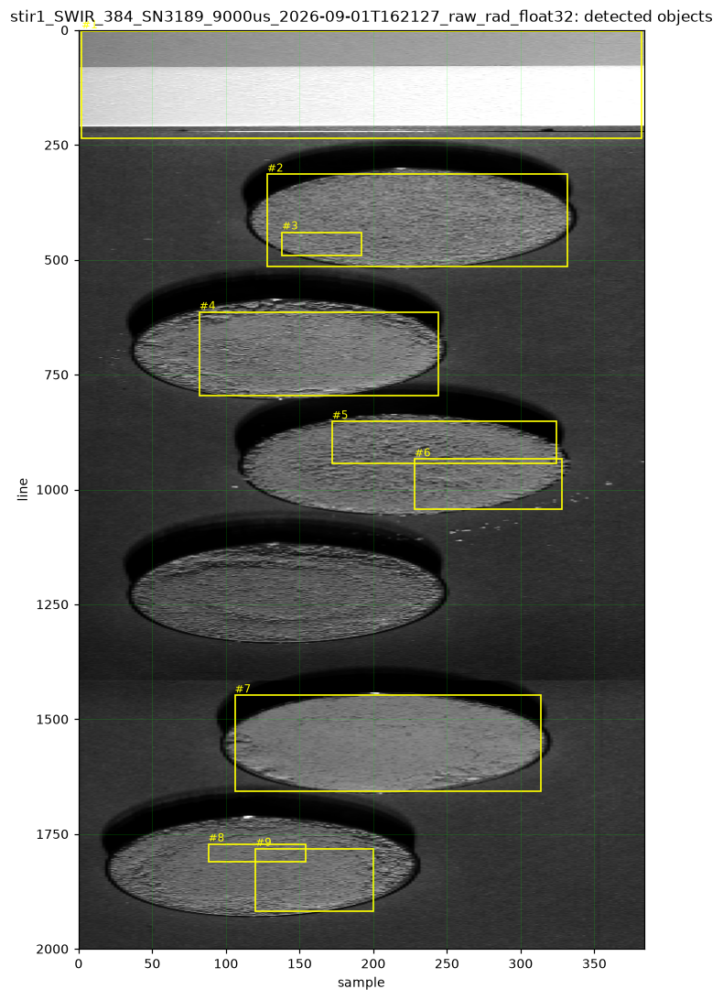


stir1_SWIR_384_SN3189_9000us_2026-09-04T161044_raw_rad_float32: Otsu threshold 0.0, 6 objects
 obj  row0  row1  col0  col1   h   w  area_px  mean_dn
   1     2   278     2   382 276 380    97744 0.054688
   2   326   538    96   314 212 218    34408 0.036904
   3   592   814    56   246 222 190    27612 0.033585
   4   874  1086    86   296 212 210    31364 0.035286
   5  1176  1368    68   236 192 168    14784 0.033314
   6  1438  1650    74   286 212 212    27056 0.033728


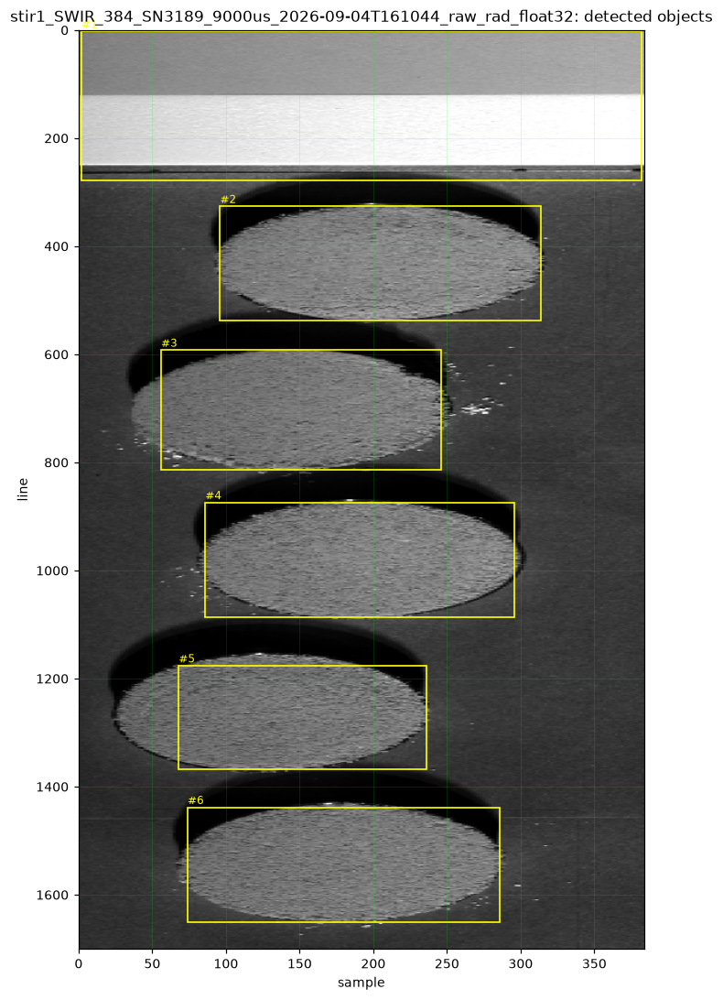


stir2_SWIR_384_SN3189_9000us_2026-09-01T163234_raw_rad_float32: Otsu threshold 0.0, 7 objects
 obj  row0  row1  col0  col1   h   w  area_px  mean_dn
   1     2   238     2   382 236 380    82376 0.062055
   2   316   522   160   326 206 166    10220 0.037394
   3   374   448   172   252  74  80     1952 0.036468
   4   476   518   156   204  42  48      896 0.037932
   5   580   772    62   250 192 188    20032 0.036766
   6  1446  1644    52   254 198 202    26716 0.035708
   7  1748  1920    98   278 172 180    16636 0.035446


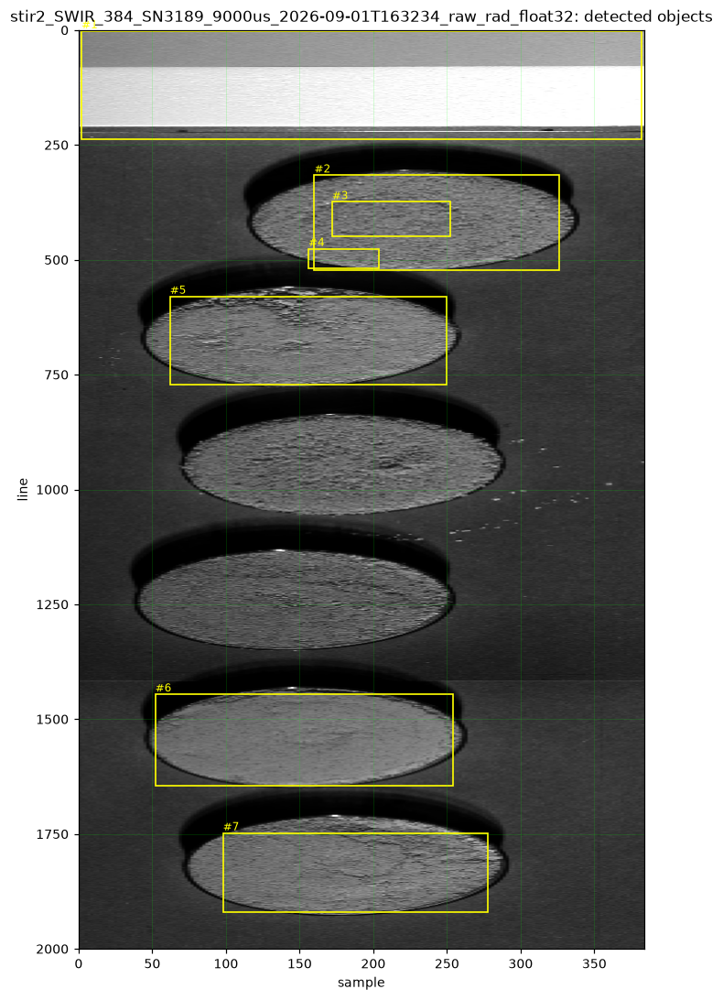


stir2_SWIR_384_SN3189_9000us_2026-09-04T161928_raw_rad_float32: Otsu threshold 0.0, 6 objects
 obj  row0  row1  col0  col1   h   w  area_px  mean_dn
   1     2   274     2   382 272 380    97304 0.054651
   2   320   530   110   316 210 206    32840 0.036603
   3   584   786    60   240 202 180    23044 0.033615
   4   856  1054    96   300 198 204    29500 0.036547
   5  1122  1306    42   212 184 170    19152 0.033885
   6  1404  1610    82   294 206 212    28180 0.034163


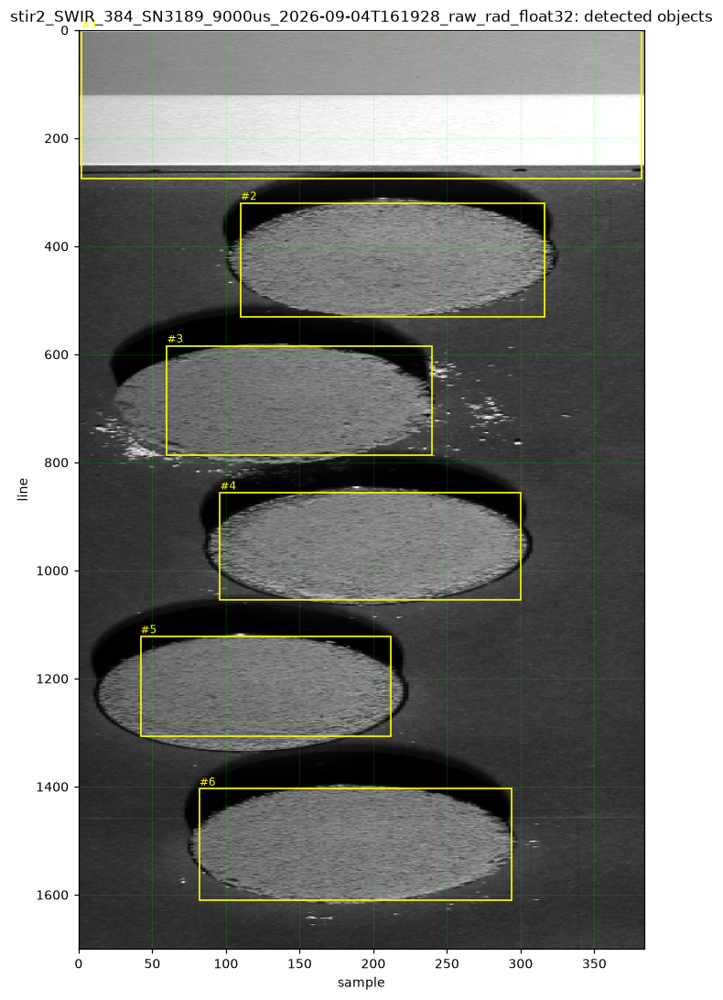


stir3_SWIR_384_SN3189_9000us_2026-09-01T164219_raw_rad_float32: Otsu threshold 0.0, 6 objects
 obj  row0  row1  col0  col1   h   w  area_px  mean_dn
   1     2   238     2   382 236 380    82144 0.062303
   2   320   532   126   326 212 200    20836 0.036892
   3   592   790    76   274 198 198    23576 0.037526
   4  1428  1640    80   288 212 208    31400 0.035756
   5  1722  1830   112   246 108 134     7420 0.035166
   6  1824  1886   110   244  62 134     4020 0.035659


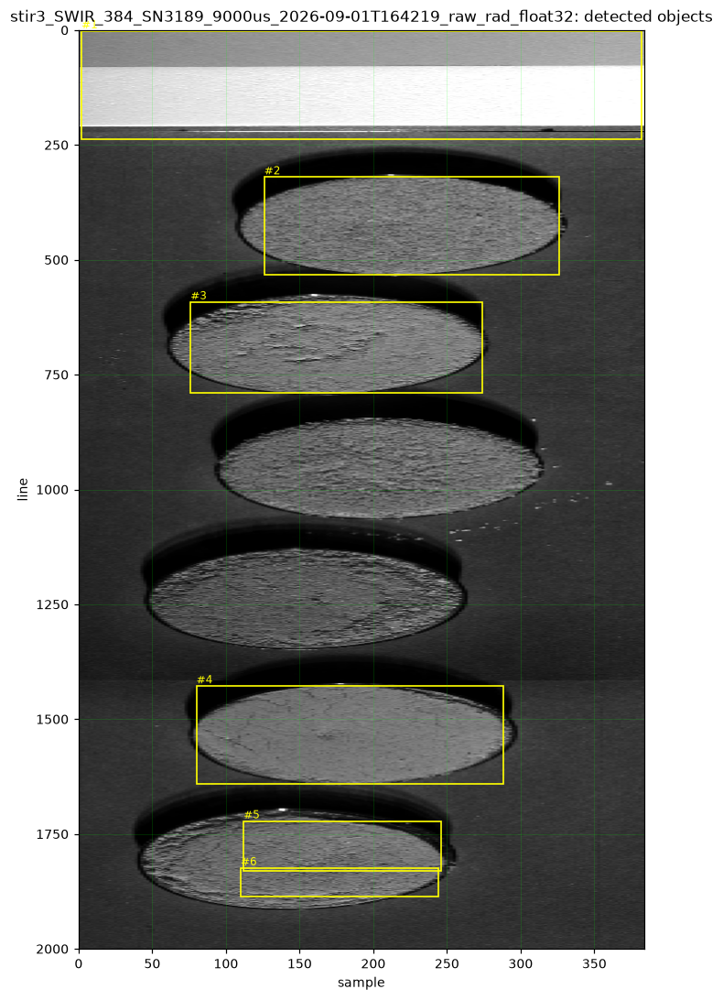


stir3_SWIR_384_SN3189_9000us_2026-09-04T162700_raw_rad_float32: Otsu threshold 0.0, 6 objects
 obj  row0  row1  col0  col1   h   w  area_px  mean_dn
   1     2   262     2   382 260 380    96400 0.054774
   2   320   532   104   318 212 214    33768 0.037199
   3   594   806    40   240 212 200    25736 0.034081
   4   860  1072    94   304 212 210    32488 0.036683
   5  1138  1348    36   224 210 188    25040 0.034170
   6  1416  1632    74   288 216 214    30384 0.034298


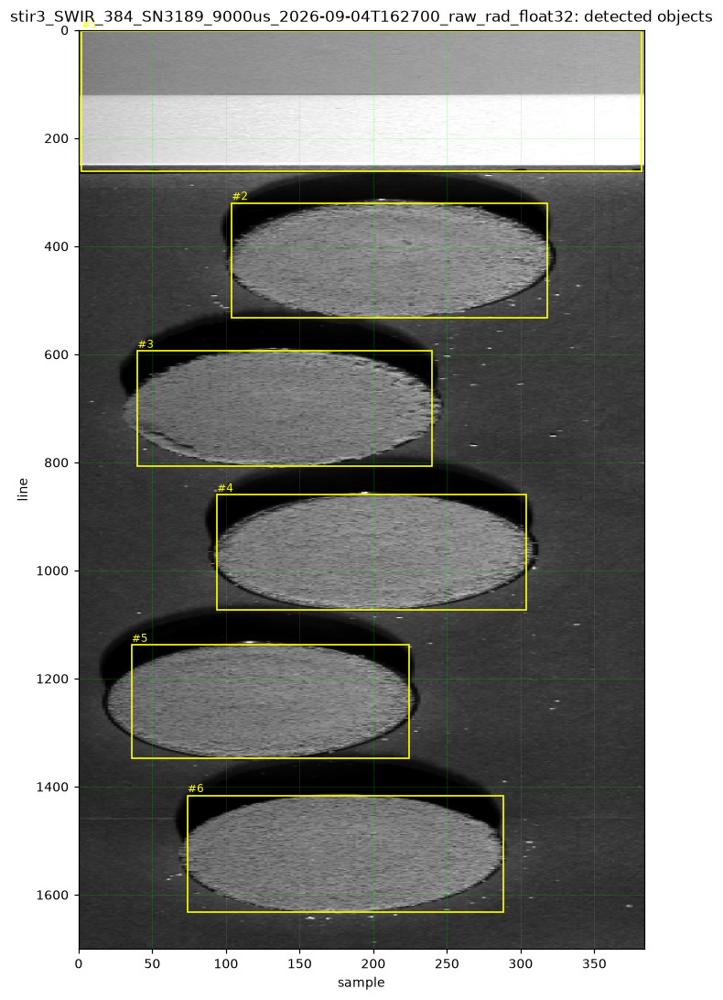

In [6]:
MIN_AREA_PX = 200          # in decimated pixels; lower it if small dishes are being dropped

def otsu(v):
    v = v[np.isfinite(v)]
    hist, edges = np.histogram(v, bins=256)
    p = hist / hist.sum(); c = np.cumsum(p)
    mids = (edges[:-1] + edges[1:]) / 2
    mu = np.cumsum(p * mids); mut = mu[-1]
    with np.errstate(divide="ignore", invalid="ignore"):
        sb = (mut * c - mu) ** 2 / (c * (1 - c))
    return mids[int(np.nanargmax(sb))]


def detect_objects(bright, st, min_area=MIN_AREA_PX):
    b = np.nan_to_num(bright, nan=0.0)
    t = otsu(b)
    m = ndimage.binary_opening(b > t, np.ones((3, 3)))
    m = ndimage.binary_closing(m, np.ones((3, 3)))
    lab, n = ndimage.label(m)
    rows = []
    for i, sl in enumerate(ndimage.find_objects(lab), start=1):
        area = int((lab[sl] == i).sum())
        if area < min_area: continue
        r0, r1 = sl[0].start * st, sl[0].stop * st
        c0, c1 = sl[1].start * st, sl[1].stop * st
        rows.append(dict(obj=len(rows) + 1, row0=r0, row1=r1, col0=c0, col1=c1,
                         h=r1 - r0, w=c1 - c0, area_px=area * st * st,
                         mean_dn=float(np.nanmean(b[sl][lab[sl] == i]))))
    df = pd.DataFrame(rows)
    if len(df):
        df = df.sort_values(["row0", "col0"]).reset_index(drop=True)
        df["obj"] = np.arange(1, len(df) + 1)
    return df, t


def annotate(bright, st, df, key):
    L, S = bright.shape[0] * st, bright.shape[1] * st
    fig, ax = plt.subplots(figsize=(6.5, 10))
    ax.imshow(stretch(bright), cmap="gray", extent=[0, S, L, 0], aspect="auto")
    for _, r in df.iterrows():
        ax.add_patch(plt.Rectangle((r.col0, r.row0), r.w, r.h, ec="yellow", fc="none", lw=1.1))
        ax.text(r.col0, r.row0 - 6, f"#{int(r.obj)}", color="yellow", fontsize=8)
    ax.set_xlabel("sample"); ax.set_ylabel("line"); ax.set_title(f"{key}: detected objects")
    ax.grid(color="lime", alpha=.25, lw=.4)
    plt.tight_layout()
    fig.savefig(QL_DIR / f"{key}_objects.png", dpi=130, bbox_inches="tight"); plt.show()

OBJECTS = {}
for key, cube in CUBES.items():
    b, st = BRIGHT[key]
    df, t = detect_objects(b, st)
    OBJECTS[key] = df
    print(f"\n{key}: Otsu threshold {t:.1f}, {len(df)} objects")
    print(df.to_string(index=False))
    annotate(b, st, df, key)

## 6. The reference certificate

Load this before locating the steps, because the certificate is what makes the steps findable.

`SRT-MS-050` is a **multi-step** target, not a plain white panel: four strips at nominally
99 / 50 / 25 / 12 %. In the 1500-1700 nm window used for the brightness image their certified reflectances
are about 0.99, 0.58, 0.34, 0.16 — so relative to the brightest strip, the radiance should fall in the
ratios **1 : 0.59 : 0.34 : 0.16**. That known pattern is a much stronger handle for finding the strips
than brightness thresholding, which drops the 12 % strip into the background.

certificate interpolated to 288 bands; 4 bands lie beyond its 2500 nm limit -> [2500.3 2505.7 2511.2 2516.6]
working range 1000.0-2450.0 nm -> 266 bands
expected step radiance ratios: [1.    0.588 0.341 0.158]


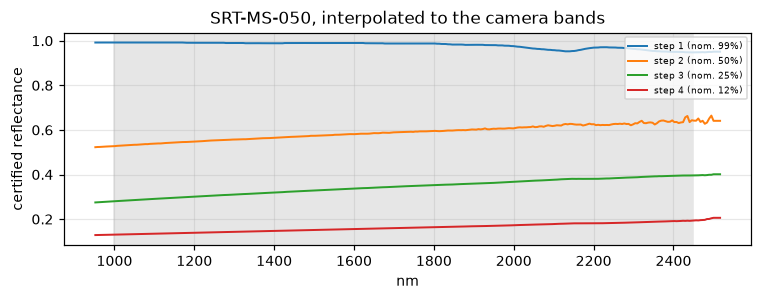

In [8]:
def load_panel(txt_path, wl):
    rows = []
    for line in Path(txt_path).read_text(errors="ignore").replace("\r", "").split("\n"):
        p = line.strip().split("\t")
        if len(p) >= 5:
            try: rows.append([float(x) for x in p[:5]])
            except ValueError: continue
    a = np.array(rows)
    R = np.column_stack([np.interp(wl, a[:, 0], a[:, 1+k]) for k in range(4)])
    return R, (wl < a[0, 0]) | (wl > a[-1, 0])

k0 = list(CUBES)[0]
WL = CUBES[k0].wl.copy()
PANEL_R, OUTSIDE = load_panel(PANEL_TXT, WL)
WL_MIN, WL_MAX = 1000.0, 2450.0
ok = (WL >= WL_MIN) & (WL <= WL_MAX)

bwin = (WL >= 1500) & (WL <= 1700)          # same window the brightness image uses
EXPECTED = PANEL_R[bwin].mean(0); EXPECTED = EXPECTED / EXPECTED[0]

print(f"certificate interpolated to {WL.size} bands; "
      f"{OUTSIDE.sum()} bands lie beyond its 2500 nm limit -> {np.round(WL[OUTSIDE],1)}")
print(f"working range {WL_MIN}-{WL_MAX} nm -> {ok.sum()} bands")
print("expected step radiance ratios:", np.round(EXPECTED, 3))

plt.figure(figsize=(7, 2.8))
for kk in range(4):
    plt.plot(WL, PANEL_R[:, kk], lw=1.3, label=f"step {kk+1} (nom. {[99,50,25,12][kk]}%)")
plt.axvspan(WL_MIN, WL_MAX, color="0.9", zorder=0)
plt.xlabel("nm"); plt.ylabel("certified reflectance"); plt.legend(fontsize=6); plt.grid(alpha=.3)
plt.title("SRT-MS-050, interpolated to the camera bands")
plt.tight_layout(); plt.show()

## 7. Finding the four steps

Brightness thresholding alone will not do this. The 12 % strip is dark enough that Otsu puts it in the
background, so the object box in section 5 covers only the bright strips — which is exactly what would
silently corrupt the calibration.

Instead: take a profile across the brightest object, normalise it by its own maximum, and look for
plateaus at the four *expected ratios* above. Both axes are tried, and whichever gives four disjoint
plateaus in the right order wins. Each is then trimmed at both ends so no rectangle straddles a boundary.

Check the drawn rectangles against the image. If it is wrong, fill in `STEPS_MANUAL` and rerun — that
overrides everything. Order is always **brightest first**, to match the certificate columns.

stir1_SWIR_384_SN3189_9000us_2026-09-01T162127_raw_rad_float32: auto: steps vary down rows
   step 1 (nom. 99%): rows 112-186, cols 78-306
   step 2 (nom. 50%): rows 14-64, cols 78-306
   step 3 (nom. 25%): rows 1520-1582, cols 78-306
   step 4 (nom. 12%): rows 1284-1352, cols 78-306
stir1_SWIR_384_SN3189_9000us_2026-09-04T161044_raw_rad_float32: a plateau collapsed after trimming
stir2_SWIR_384_SN3189_9000us_2026-09-01T163234_raw_rad_float32: auto: steps vary down rows
   step 1 (nom. 99%): rows 108-186, cols 78-306
   step 2 (nom. 50%): rows 16-64, cols 78-306
   step 3 (nom. 25%): rows 1520-1568, cols 78-306
   step 4 (nom. 12%): rows 1310-1372, cols 78-306
stir2_SWIR_384_SN3189_9000us_2026-09-04T161928_raw_rad_float32: a plateau collapsed after trimming
stir3_SWIR_384_SN3189_9000us_2026-09-01T164219_raw_rad_float32: auto: steps vary down rows
   step 1 (nom. 99%): rows 198-206, cols 78-306
   step 2 (nom. 50%): rows 14-64, cols 78-306
   step 3 (nom. 25%): rows 1506-1558, cols 78-3

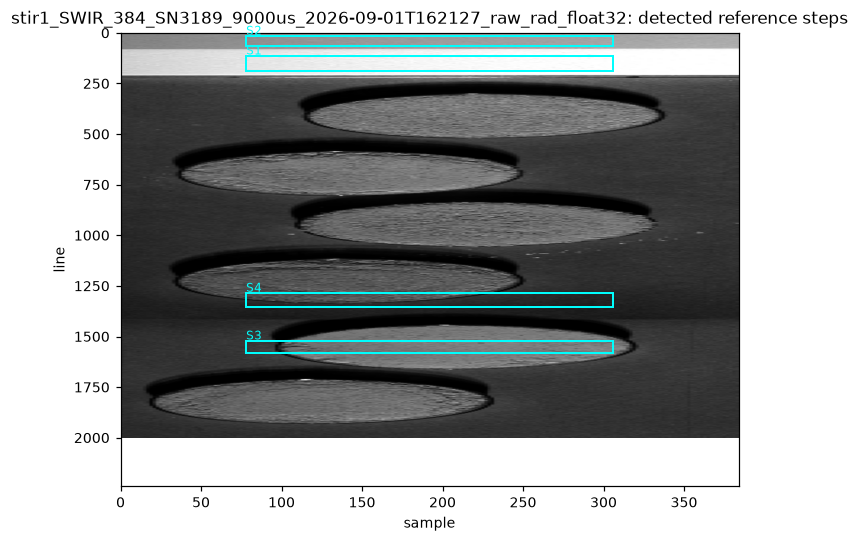

In [9]:
STEP_MARGIN  = 0.20        # fraction trimmed from each end of a detected plateau
STEPS_MANUAL = {}          # e.g. {"stir1_...": [(30,90,60,120), (30,90,130,190), ...]}

def _runs(mask, min_len=3):
    out, s = [], None
    for i, v in enumerate(np.append(mask, False)):
        if v and s is None: s = i
        elif not v and s is not None:
            if i - s >= min_len: out.append((s, i))
            s = None
    return out

def find_steps(bright, st, df, key):
    if key in STEPS_MANUAL:
        return STEPS_MANUAL[key], "manual override"
    if not len(df):
        return None, "no objects detected"
    r = df.loc[df["mean_dn"].idxmax()]                      # brightest object = the white strip
    R0, R1 = int(r.row0 / st), int(r.row1 / st)
    C0, C1 = int(r.col0 / st), int(r.col1 / st)

    for across in (True, False):
        prof = (np.nanmedian(bright[R0:R1, :], axis=0) if across
                else np.nanmedian(bright[:, C0:C1], axis=1))
        p = prof / np.nanmax(prof)
        segs = []
        for lev in EXPECTED:
            cand = _runs(np.abs(p - lev) < max(0.04, 0.15 * lev))
            if not cand: break
            segs.append(max(cand, key=lambda q: q[1] - q[0]))
        if len(segs) != 4:
            continue
        srt = sorted(segs)
        if not all(srt[i][1] <= srt[i + 1][0] for i in range(3)):
            continue                                        # plateaus overlap -> wrong axis

        rois = []
        for (a, b) in segs:
            pad = max(1, int((b - a) * STEP_MARGIN)); a, b = a + pad, b - pad
            if b - a < 2: return None, "a plateau collapsed after trimming"
            if across:
                h = R1 - R0
                rois.append((int((R0 + h * 0.2) * st), int((R1 - h * 0.2) * st),
                             int(a * st), int(b * st)))
            else:
                w = C1 - C0
                rois.append((int(a * st), int(b * st),
                             int((C0 + w * 0.2) * st), int((C1 - w * 0.2) * st)))
        return rois, f"auto: steps vary {'across columns' if across else 'down rows'}"
    return None, "could not match the 1 : 0.59 : 0.34 : 0.16 pattern -- set STEPS_MANUAL"


STEPS = {}
for key, cube in CUBES.items():
    b, st = BRIGHT[key]
    rois, how = find_steps(b, st, OBJECTS[key], key)
    STEPS[key] = rois
    print(f"{key}: {how}")
    if rois:
        for i, q in enumerate(rois, 1):
            print(f"   step {i} (nom. {[99,50,25,12][i-1]}%): rows {q[0]}-{q[1]}, cols {q[2]}-{q[3]}")

if STEPS.get(k0):
    b, st = BRIGHT[k0]
    L, S = b.shape[0]*st, b.shape[1]*st
    fig, ax = plt.subplots(figsize=(6.5, 5))
    ax.imshow(stretch(b), cmap="gray", extent=[0, S, L, 0], aspect="auto")
    for i, (r0, r1, c0, c1) in enumerate(STEPS[k0], 1):
        ax.add_patch(plt.Rectangle((c0, r0), c1-c0, r1-r0, ec="cyan", fc="none", lw=1.3))
        ax.text(c0, r0-5, f"S{i}", color="cyan", fontsize=8)
    lo = min(q[0] for q in STEPS[k0]); hi = max(q[1] for q in STEPS[k0])
    ax.set_ylim(hi + 0.4*(hi-lo) + 30, max(0, lo - 0.4*(hi-lo) - 30))
    ax.set_title(f"{k0}: detected reference steps"); ax.set_xlabel("sample"); ax.set_ylabel("line")
    plt.tight_layout(); plt.savefig(QL_DIR / f"{k0}_steps.png", dpi=130, bbox_inches="tight"); plt.show()

## 8. Is the radiance already dark-corrected?

You did not know. The four-step target answers it without a dark frame.

Under fixed illumination a diffuse scene is linear in reflectance, so per band

    L = a*R + b

fit across the four steps. **`b` is the additive offset** — residual dark current plus stray light. Near
zero means the vendor's radiance conversion already removed it, and a plain white-ratio conversion is
valid. The R² of the same fit is a free check on the step ROIs: below ~0.995 usually means a rectangle is
straddling a boundary or catching a specular highlight.

stir1_SWIR_384_SN3189_9000us_2026-09-01T162127_raw_rad_float32: median |offset| = 0.1132 refl. units, median linearity R2 = 0.96782
stir2_SWIR_384_SN3189_9000us_2026-09-01T163234_raw_rad_float32: median |offset| = 0.0925 refl. units, median linearity R2 = 0.97743
stir3_SWIR_384_SN3189_9000us_2026-09-01T164219_raw_rad_float32: median |offset| = 0.1158 refl. units, median linearity R2 = 0.94546

USE_OFFSET = True -> subtract the fitted offset


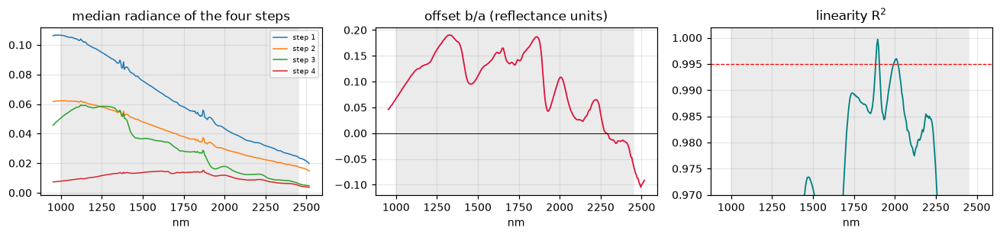

In [10]:
def step_radiances(cube, rois):
    return np.array([np.nanmedian(cube.region(*q).reshape(-1, cube.wl.size), axis=0) for q in rois])

def fit_offset(L_steps, R_cert):
    n = L_steps.shape[0]
    a = np.full(L_steps.shape[1], np.nan); b = a.copy(); r2 = a.copy()
    for jj in range(L_steps.shape[1]):
        y = L_steps[:, jj]
        if not np.all(np.isfinite(y)): continue
        A = np.column_stack([R_cert[jj, :n], np.ones(n)])
        c, *_ = np.linalg.lstsq(A, y, rcond=None)
        a[jj], b[jj] = c
        ss = np.sum((y - y.mean())**2)
        r2[jj] = 1 - np.sum((y - A@c)**2)/ss if ss > 0 else np.nan
    return a, b, r2

DIAG = {}
for key, cube in CUBES.items():
    if not STEPS[key]: continue
    Ls = step_radiances(cube, STEPS[key])
    a, b, r2 = fit_offset(Ls, PANEL_R)
    rel = b / np.maximum(a, 1e-12)
    DIAG[key] = dict(a=a, b=b, r2=r2, L=Ls,
                     med_off=float(np.nanmedian(np.abs(rel[ok]))),
                     med_r2=float(np.nanmedian(r2[ok])))
    print(f"{key}: median |offset| = {DIAG[key]['med_off']:.4f} refl. units, "
          f"median linearity R2 = {DIAG[key]['med_r2']:.5f}")

USE_OFFSET = bool(np.nanmedian([d["med_off"] for d in DIAG.values()]) >= 0.005) if DIAG else False
print("\nUSE_OFFSET =", USE_OFFSET,
      "-> subtract the fitted offset" if USE_OFFSET else "-> data is effectively dark-corrected")

if DIAG:
    d = DIAG[k0]
    fig, axs = plt.subplots(1, 3, figsize=(12, 2.9))
    for i in range(4): axs[0].plot(WL, d["L"][i], lw=1, label=f"step {i+1}")
    axs[0].set_title("median radiance of the four steps"); axs[0].legend(fontsize=6)
    axs[1].plot(WL, d["b"]/np.maximum(d["a"],1e-12), lw=1.2, color="crimson")
    axs[1].axhline(0, color="k", lw=.6); axs[1].set_title("offset b/a (reflectance units)")
    axs[2].plot(WL, d["r2"], lw=1.2, color="teal"); axs[2].set_ylim(.97, 1.002)
    axs[2].axhline(.995, color="r", ls="--", lw=.8); axs[2].set_title("linearity R$^2$")
    for ax in axs:
        ax.axvspan(WL_MIN, WL_MAX, color="0.92", zorder=0); ax.set_xlabel("nm"); ax.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(QL_DIR / f"{k0}_offset_check.png", dpi=120, bbox_inches="tight")
    plt.show()

## 9. Radiance to reflectance — using all four steps

The obvious conversion divides by the white strip. That works only if the white strip spans the whole
swath, and yours does not — it is far narrower than 384 pixels. Divide by a single narrow strip and every
dish sitting at a different across-track position inherits the lens vignetting as a spectral error.

The four-step target solves this. Each strip gives an independent estimate of the instrument's
**gain-times-illumination** term at the columns it covers:

    G(col, band) = (L_step(col, band) - b) / R_certified(band)

and the four strips together span far more of the swath than the white one alone. Where strips overlap in
column, the estimates are averaged, weighted toward the brighter strips since they carry better SNR. A
low-order polynomial extends `G` across any remaining columns. Then simply

    R_sample(col, band) = (L - b) / G(col, band)

No separate white-reference step, and the wavelength dependence of the certificate is already baked in —
which matters, because the white strip is not flat 0.99, it falls to 0.948 by 2450 nm.

**The QC below is leave-one-step-out.** Rebuild `G` from three strips, predict the fourth, compare against
its certificate. That keeps the check honest: if all four were used to build `G` and then checked against
it, the test would be circular and would pass no matter what.

stir1_SWIR_384_SN3189_9000us_2026-09-01T162127_raw_rad_float32: the four steps cover 59.4% of the swath; polynomial fills the rest (residual 2.04%)
stir2_SWIR_384_SN3189_9000us_2026-09-01T163234_raw_rad_float32: the four steps cover 59.4% of the swath; polynomial fills the rest (residual 1.50%)
stir3_SWIR_384_SN3189_9000us_2026-09-01T164219_raw_rad_float32: the four steps cover 59.4% of the swath; polynomial fills the rest (residual 1.24%)


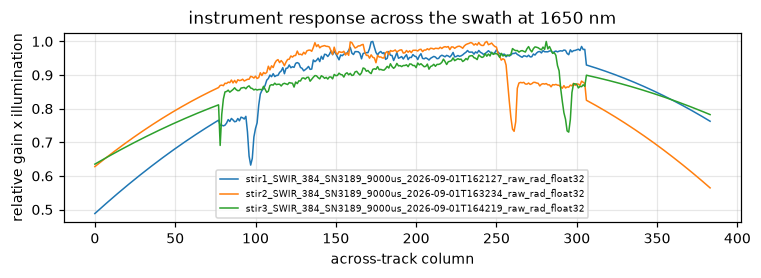

In [11]:
def build_gain(cube, rois, R_cert, b=None, use=(0,1,2,3), deg=2):
    # G = (L - b) / R_cert, accumulated per across-track column from the chosen steps.
    S, B = cube.shape[1], cube.wl.size
    num = np.zeros((S, B)); den = np.zeros((S, B))
    for k in use:
        r0, r1, c0, c1 = rois[k]
        L = np.nanmedian(cube.region(r0, r1, c0, c1), axis=0)          # (cols, bands)
        if b is not None: L = L - b[None, :]
        g = L / np.maximum(R_cert[:, k][None, :], 1e-6)
        w = np.broadcast_to(R_cert[:, k][None, :], g.shape)             # brighter step, more weight
        good = np.isfinite(g)
        num[c0:c1] += np.where(good, g * w, 0.0)
        den[c0:c1] += np.where(good, w, 0.0)
    G = np.where(den > 0, num / np.maximum(den, 1e-12), np.nan)
    cov = float(np.mean(np.any(den > 0, axis=1)))

    have = np.any(den > 0, axis=1)
    if cov < 0.999 and have.sum() > deg + 2:
        x  = (np.where(have)[0] - S/2) / (S/2)
        xa = (np.arange(S) - S/2) / (S/2)
        V, Va = np.vander(x, deg+1), np.vander(xa, deg+1)
        coef, *_ = np.linalg.lstsq(V, G[have], rcond=None)
        fit = Va @ coef
        resid = float(np.nanmedian(np.abs(V @ coef - G[have]) / np.maximum(G[have], 1e-9)))
        G = np.where(have[:, None], G, fit)                              # keep measured, fill the rest
    else:
        resid = 0.0
    return G, cov, resid


def to_reflectance(cube, reg, c0, G, b=None, sat=1.6):
    g = G[c0:c0+reg.shape[1], :][None, :, :]
    R = ((reg - b[None, None, :]) if b is not None else reg) / np.maximum(g, 1e-9)
    R[(R < -0.05) | (R > sat)] = np.nan
    return R


GAIN = {}
for key, cube in CUBES.items():
    if not STEPS[key]: continue
    b_use = DIAG[key]["b"] if USE_OFFSET else None
    G, cov, resid = build_gain(cube, STEPS[key], PANEL_R, b_use)
    GAIN[key] = G
    print(f"{key}: the four steps cover {cov*100:.1f}% of the swath"
          + (f"; polynomial fills the rest (residual {resid*100:.2f}%)" if cov < 0.999 else ""))

jj = int(np.argmin(np.abs(WL - 1650)))
plt.figure(figsize=(7, 2.6))
for key, G in GAIN.items():
    plt.plot(G[:, jj] / np.nanmax(G[:, jj]), lw=1, label=key)
plt.xlabel("across-track column"); plt.ylabel("relative gain x illumination")
plt.title("instrument response across the swath at 1650 nm")
plt.legend(fontsize=6); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(QL_DIR / "illumination_profile.png", dpi=120, bbox_inches="tight"); plt.show()

stir1_SWIR_384_SN3189_9000us_2026-09-01T162127_raw_rad_float32: leave-one-out error vs certificate  step1 0.0385  step2 0.0373  step3 0.1217  step4 0.0742   CHECK
stir2_SWIR_384_SN3189_9000us_2026-09-01T163234_raw_rad_float32: leave-one-out error vs certificate  step1 0.0547  step2 0.0354  step3 0.1109  step4 0.0686   CHECK
stir3_SWIR_384_SN3189_9000us_2026-09-01T164219_raw_rad_float32: leave-one-out error vs certificate  step1 0.0322  step2 0.0282  step3 0.1382  step4 0.0816   CHECK


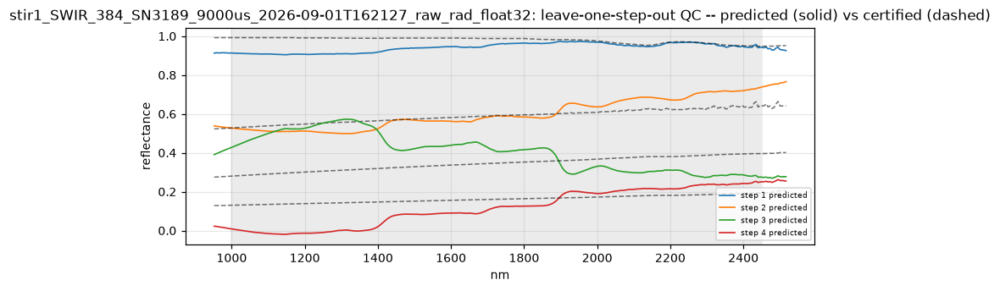


Under ~0.02 means the reflectance scale is sound. The darkest step is always the worst --
it has the least signal -- so judge mainly on steps 1 to 3.


In [12]:
# ---- leave-one-step-out QC ----
QC = {}
fig, ax = plt.subplots(figsize=(7.5, 3.2))
for key, cube in CUBES.items():
    if key not in GAIN: continue
    b_use = DIAG[key]["b"] if USE_OFFSET else None
    errs = []
    for kk in range(4):
        others = tuple(i for i in range(4) if i != kk)
        Gk, _, _ = build_gain(cube, STEPS[key], PANEL_R, b_use, use=others)
        r0, r1, c0, c1 = STEPS[key][kk]
        Rk = to_reflectance(cube, cube.region(r0, r1, c0, c1), c0, Gk, b_use)
        meas = np.nanmedian(Rk.reshape(-1, WL.size), axis=0)
        errs.append(float(np.nanmean(np.abs(meas[ok] - PANEL_R[ok, kk]))))
        if key == k0:
            ax.plot(WL, meas, lw=1.1, label=f"step {kk+1} predicted")
            ax.plot(WL, PANEL_R[:, kk], lw=1, ls="--", color="k", alpha=.55)
    QC[key] = errs
    print(f"{key}: leave-one-out error vs certificate  "
          + "  ".join(f"step{i+1} {e:.4f}" for i, e in enumerate(errs))
          + f"   {'OK' if max(errs) < 0.02 else 'CHECK'}")

ax.axvspan(WL_MIN, WL_MAX, color="0.92", zorder=0)
ax.set_xlabel("nm"); ax.set_ylabel("reflectance"); ax.legend(fontsize=6); ax.grid(alpha=.3)
ax.set_title(f"{k0}: leave-one-step-out QC -- predicted (solid) vs certified (dashed)")
plt.tight_layout(); plt.savefig(QL_DIR / "conversion_qc.png", dpi=120, bbox_inches="tight"); plt.show()

print("\nUnder ~0.02 means the reflectance scale is sound. The darkest step is always the worst --")
print("it has the least signal -- so judge mainly on steps 1 to 3.")

## 10. Spectra

Mean reflectance of every detected object, with a margin trimmed off each box so the dish rim and the
meniscus at the powder edge do not contribute.

What to look for, in the 1000-2450 nm working range:

- **1450 and 1940 nm** — water. Usually the deepest features; they say more about moisture and roast than
  about chicory content.
- **1730 nm** — first C-H stretch overtone, lipids. Coffee carries roughly 10-15 % oil, chicory
  almost none, so this is where the two should visibly part company.
- **2100 nm** — carbohydrate C-O and O-H. Chicory is inulin-rich, so expect the chicory trace to sit
  lower here.
- **2300-2350 nm** — C-H combination. Typically the most discriminating region of the whole range.

If two objects you know to be different (pure robusta and pure chicory) overlay almost exactly, something
is wrong with the conversion, not with the coffee.

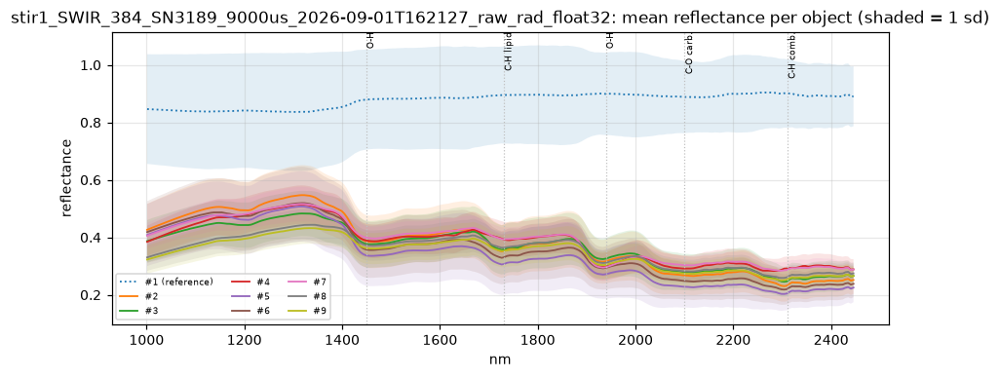

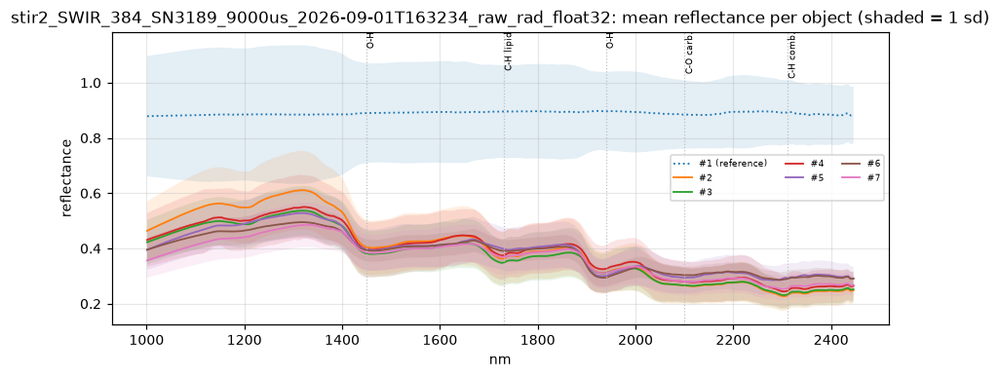

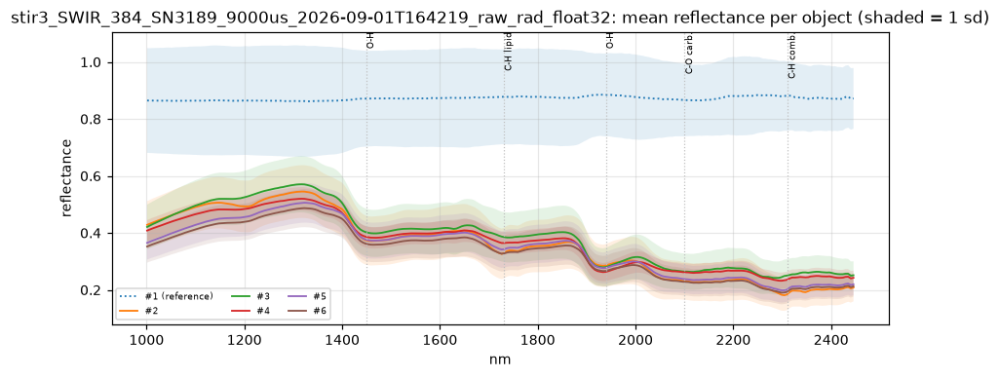

spectra written to inspect_out/object_mean_reflectance.csv


In [13]:
TRIM = 0.18      # fraction trimmed from each side of an object box before averaging

def object_spectra(cube, df, G, b_use, trim=TRIM):
    out = {}
    for _, r in df.iterrows():
        h, w = r.row1 - r.row0, r.col1 - r.col0
        r0 = int(r.row0 + h*trim); r1 = int(r.row1 - h*trim)
        c0 = int(r.col0 + w*trim); c1 = int(r.col1 - w*trim)
        if r1 - r0 < 3 or c1 - c0 < 3: continue
        R = to_reflectance(cube, cube.region(r0, r1, c0, c1), c0, G, b_use)
        flat = R.reshape(-1, WL.size)
        out[int(r.obj)] = dict(mean=np.nanmean(flat, axis=0), sd=np.nanstd(flat, axis=0),
                               box=(r0, r1, c0, c1), n=int(np.isfinite(flat[:, jj]).sum()))
    return out

SPECTRA = {}
for key, cube in CUBES.items():
    if key not in GAIN: continue
    SPECTRA[key] = object_spectra(cube, OBJECTS[key], GAIN[key],
                                  DIAG[key]["b"] if USE_OFFSET else None)

for key, sp in SPECTRA.items():
    # the brightest object is the reference target; its "spectrum" averages the four
    # steps and is only a flatness sanity check, not a material spectrum
    ref_id = int(OBJECTS[key].loc[OBJECTS[key]["mean_dn"].idxmax(), "obj"])
    fig, ax = plt.subplots(figsize=(8, 3.6))
    for oid, d in sp.items():
        tag = f"#{oid} (reference)" if oid == ref_id else f"#{oid}"
        ax.plot(WL[ok], d["mean"][ok], lw=1.2, ls=":" if oid == ref_id else "-", label=tag)
        ax.fill_between(WL[ok], (d["mean"]-d["sd"])[ok], (d["mean"]+d["sd"])[ok], alpha=.12)
    for nm, t in [(1450,"O-H"), (1730,"C-H lipid"), (1940,"O-H"), (2100,"C-O carb."), (2310,"C-H comb.")]:
        ax.axvline(nm, color="0.75", lw=.8, ls=":")
        ax.text(nm, ax.get_ylim()[1], t, fontsize=6, rotation=90, va="top")
    ax.set_xlabel("nm"); ax.set_ylabel("reflectance"); ax.grid(alpha=.3)
    ax.legend(fontsize=6, ncol=3); ax.set_title(f"{key}: mean reflectance per object (shaded = 1 sd)")
    plt.tight_layout(); plt.savefig(QL_DIR / f"{key}_spectra.png", dpi=130, bbox_inches="tight"); plt.show()

rows = []
for key, sp in SPECTRA.items():
    for oid, d in sp.items():
        rows.append(dict(scan=key, obj=oid, **{f"{w:.1f}": v for w, v in zip(WL[ok], d["mean"][ok])}))
pd.DataFrame(rows).to_csv(OUT / "object_mean_reflectance.csv", index=False)
print("spectra written to", OUT / "object_mean_reflectance.csv")

## 11. Report

Run this and paste the output to me along with the PNGs from `./quicklooks/`.

Tell me at the same time which object number is which specimen — e.g. *"object 1 is the reference,
2 is AB100, 3 is CH100..."*. Once I have the arrangement and these numbers I can fill in the ROI cell of
the modelling notebook for you, and we can go straight to calibration.

In [14]:
lines = ["=" * 72, "SWIR INSPECTION REPORT", "=" * 72]
for key, cube in CUBES.items():
    lines += [f"\n[{key}]  {cube.hdr_path.name}",
              f"  {cube.shape[0]} lines x {cube.shape[1]} samples x {cube.shape[2]} bands, "
              f"{cube.h['interleave']}, offset {cube.offset} ({cube.offset_reason})",
              f"  {cube.wl[0]:.1f}-{cube.wl[-1]:.1f} nm | ignore={cube.ignore} | "
              f"layout: {ORIENT.get(key,'?')}"]
    if key in DIAG:
        lines.append(f"  offset |b/a| = {DIAG[key]['med_off']:.4f} | linearity R2 = {DIAG[key]['med_r2']:.5f}")
    if key in QC:
        lines.append("  leave-one-step-out QC: "
                     + " ".join(f"step{i+1} {e:.4f}" for i, e in enumerate(QC[key])))
    if STEPS.get(key):
        lines.append("  reference steps (row0,row1,col0,col1), brightest first:")
        for i, q in enumerate(STEPS[key], 1): lines.append(f"     S{i}: {q}")
    df = OBJECTS.get(key)
    if df is not None and len(df):
        lines.append(f"  {len(df)} objects detected:")
        for _, r in df.iterrows():
            lines.append(f"     #{int(r.obj):2d}  rows {int(r.row0):5d}-{int(r.row1):5d}  "
                         f"cols {int(r.col0):4d}-{int(r.col1):4d}  "
                         f"({int(r.h)}x{int(r.w)} px)  mean DN {r.mean_dn:.0f}")
    if key in SPECTRA:
        for oid, d in SPECTRA[key].items():
            m = d["mean"]
            def at(nm): return m[int(np.argmin(np.abs(WL - nm)))]
            lines.append(f"     #{oid:2d} reflectance  1200:{at(1200):.3f}  1450:{at(1450):.3f}  "
                         f"1730:{at(1730):.3f}  2100:{at(2100):.3f}  2310:{at(2310):.3f}")
lines += ["", f"USE_OFFSET = {USE_OFFSET}", f"working range = {WL_MIN}-{WL_MAX} nm ({ok.sum()} bands)",
          "=" * 72]
report = "\n".join(lines)
print(report)
(OUT / "inspection_report.txt").write_text(report)
print("\nsaved to", OUT / "inspection_report.txt")
print("PNGs in", QL_DIR.resolve())

SWIR INSPECTION REPORT

[stir1_SWIR_384_SN3189_9000us_2026-09-01T162127_raw_rad_float32]  stir1_SWIR_384_SN3189_9000us_2026-09-01T162127_raw_rad_float32.hdr
  2000 lines x 384 samples x 288 bands, bil, offset 2666496 (declared offset matches)
  952.2-2516.6 nm | ignore=2.0 | layout: along-track (down the scan)
  offset |b/a| = 0.1132 | linearity R2 = 0.96782
  leave-one-step-out QC: step1 0.0385 step2 0.0373 step3 0.1217 step4 0.0742
  reference steps (row0,row1,col0,col1), brightest first:
     S1: (112, 186, 78, 306)
     S2: (14, 64, 78, 306)
     S3: (1520, 1582, 78, 306)
     S4: (1284, 1352, 78, 306)
  9 objects detected:
     # 1  rows     2-  236  cols    2- 382  (234x380 px)  mean DN 0
     # 2  rows   314-  514  cols  128- 332  (200x204 px)  mean DN 0
     # 3  rows   440-  490  cols  138- 192  (50x54 px)  mean DN 0
     # 4  rows   614-  796  cols   82- 244  (182x162 px)  mean DN 0
     # 5  rows   852-  944  cols  172- 324  (92x152 px)  mean DN 0
     # 6  rows   934- 1042 